- Instituto Tecnológico De Estudios Superiores de Monterrey
- Maestría en Inteligencia Artificial Aplicada (MSNA)
- Materia: Operaciones de Aprendizaje Automático
- Ejercicio Semana 3. Notebook Baseline
-------------------------------------------------------------------------------------------------
- Alumno: Oscar Alfonso Valenzuela Muñoz
- No. Cuenta: A01840486
- Mail: A01840486@tec.mx

Fecha: 04-10-26

#### Objetivo(s)
 
Demostrar de forma individual el dominio de los fundamentos del flujo de modelado en Machine Learning: explorar y limpiar un conjunto de datos, entrenar y evaluar un modelo base, y registrar el experimento en MLFlow Tracking, dejando evidencia reproducible del punto de partida.
Esta actividad impacta en el siguiente objetivo de aprendizaje:

- Construir, registrar, ajustar y evaluar modelos de Machine Learning, comprendiendo y aplicando las mejores prácticas para cada etapa del pipeline de modelado.

#### Instrucciones
 
Esta actividad funciona como filtro diagnóstico: te permitirá autoevaluar si cuentas con las bases necesarias para el resto del curso e identificar a tiempo los temas que conviene reforzar.

En esta actividad trabajarás de forma individual con un conjunto de datos para recorrer el flujo básico de un proyecto de Machine Learning. El objetivo no es lograr el mejor modelo posible, sino demostrar que dominas cada etapa del proceso y que sabes registrar tu trabajo de forma reproducible. Te recomendamos utilizar el dataset que tu equipo eligió para el proyecto; en su defecto, puedes usar un dataset público de Kaggle o del UCI Machine Learning Repository.

Realiza los siguientes pasos:

- Paso 1: Carga y describe el dataset:

Importa los datos en un notebook.
Describe su estructura (número de registros, variables, tipos y significado).

- Paso 2: Realiza un análisis exploratorio (EDA):

Genera estadísticas descriptivas y visualizaciones que te permitan entender la distribución de las variables y las relaciones entre ellas.

- Paso 3: Limpia los datos:

Identifica y trata valores faltantes, duplicados, outliers y tipos incorrectos.
Documenta cada decisión que tomes.

- Paso 4: Entrena un modelo base:

Selecciona un modelo sencillo (baseline) apropiado para el problema.
Divide los datos en entrenamiento y prueba, y entrénalo.

- Paso 5: Evalúa el modelo:

Calcula al menos una métrica de desempeño coherente con el tipo de problema.
Interpreta el resultado de manera detallada.
- Paso 6: Registra el experimento en MLFlow:

Usa MLFlow Tracking para registrar parámetros y métricas.
Solo si aplica, registra los artefactos del modelo base.
- Paso 7: Redacta una reflexión:

Al final del notebook, explica brevemente qué mejorarías en este flujo aplicando prácticas de MLOps y por qué.
¿Cómo se ven reflejados estos aprendizajes dentro de tu área profesional?
150 palabras o más de extensión. 

# Solución propuesta

Dataset Seleccionado: Subramaniyan, M. (2023). Paddy Dataset [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55W3J.

### 1. Carga y descripción del dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Cargar el dataset directamente desde el archivo zip
import zipfile
with zipfile.ZipFile('../data/paddy+dataset.zip', 'r') as z:
    with z.open('paddydataset.csv') as f:
        df = pd.read_csv(f)

df.head()

,Hectares,Agriblock,Variety,Soil Types,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery,Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,...,Wind Direction_D1_D30,Wind Direction_D31_D60,Wind Direction_D61_D90,Wind Direction_D91_D120,Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
0,6,Cuddalore,CO_43,alluvial,150,75.0,dry,120,6,240,...,SW,W,NNW,WSW,72.0,78,88,85,540,35028
1,6,Kurinjipadi,ponmani,clay,150,75.0,wet,120,6,240,...,NW,S,SE,SSE,64.6,85,84,87,600,35412
2,6,Panruti,delux ponni,alluvial,150,75.0,dry,120,6,240,...,ENE,NE,NNE,W,85.0,96,84,79,600,36300
3,6,Kallakurichi,CO_43,clay,150,75.0,wet,120,6,240,...,W,WNW,SE,S,88.5,95,81,84,540,35016
4,6,Sankarapuram,ponmani,alluvial,150,75.0,dry,120,6,240,...,SSE,W,SW,NW,72.7,91,83,81,600,34044


Descripción de la estructura del dataset:

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2789 entries, 0 to 2788
Data columns (total 45 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Hectares                            2789 non-null   int64  
 1   Agriblock                           2789 non-null   str    
 2   Variety                             2789 non-null   str    
 3   Soil Types                          2789 non-null   str    
 4   Seedrate(in Kg)                     2789 non-null   int64  
 5   LP_Mainfield(in Tonnes)             2789 non-null   float64
 6   Nursery                             2789 non-null   str    
 7   Nursery area (Cents)                2789 non-null   int64  
 8   LP_nurseryarea(in Tonnes)           2789 non-null   int64  
 9   DAP_20days                          2789 non-null   int64  
 10  Weed28D_thiobencarb                 2789 non-null   int64  
 11  Urea_40Days                         2789 non-null   fl

### 2. Análisis Exploratorio (EDA)

In [3]:
# Estadísticas descriptivas
df.describe()

,Hectares,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,Weed28D_thiobencarb,Urea_40Days,Potassh_50Days,Micronutrients_70Days,...,Inst Wind Speed_D1_D30(in Knots),Inst Wind Speed_D31_D60(in Knots),Inst Wind Speed_D61_D90(in Knots),Inst Wind Speed_D91_D120(in Knots),Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
count,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,...,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000
mean,3.717461,92.936536,46.468268,74.349229,3.717461,148.698458,7.434923,100.854729,38.587250,55.761922,...,7.233417,8.512729,8.172822,9.449265,76.256938,87.594120,85.160272,83.859448,335.510936,22517.728935
std,1.437777,35.944420,17.972210,28.755536,1.437777,57.511072,2.875554,39.006885,14.924123,21.566652,...,2.566549,3.203679,1.993596,2.516664,8.001361,6.776736,3.492529,3.134875,134.314772,9199.661393
min,1.000000,25.000000,12.500000,20.000000,1.000000,40.000000,2.000000,27.130000,10.380000,15.000000,...,4.000000,4.000000,4.000000,6.000000,64.600000,78.000000,81.000000,79.000000,80.000000,5410.000000
25%,3.000000,75.000000,37.500000,60.000000,3.000000,120.000000,6.000000,81.390000,31.140000,45.000000,...,4.000000,6.000000,8.000000,6.000000,72.000000,80.000000,83.000000,81.000000,240.000000,16389.000000
50%,4.000000,100.000000,50.000000,80.000000,4.000000,160.000000,8.000000,108.520000,41.520000,60.000000,...,8.000000,10.000000,8.000000,10.000000,72.700000,91.000000,84.000000,84.000000,360.000000,24636.000000
75%,5.000000,125.000000,62.500000,100.000000,5.000000,200.000000,10.000000,135.650000,51.900000,75.000000,...,10.000000,12.000000,10.000000,12.000000,85.000000,95.000000,88.000000,87.000000,450.000000,31035.000000
max,6.000000,150.000000,75.000000,120.000000,6.000000,240.000000,12.000000,162.780000,62.280000,90.000000,...,10.000000,12.000000,10.000000,12.000000,88.500000,96.000000,92.000000,88.000000,600.000000,38814.000000


Visualización de la distribución de la variable objetivo y la relación con la variedad del cultivo.

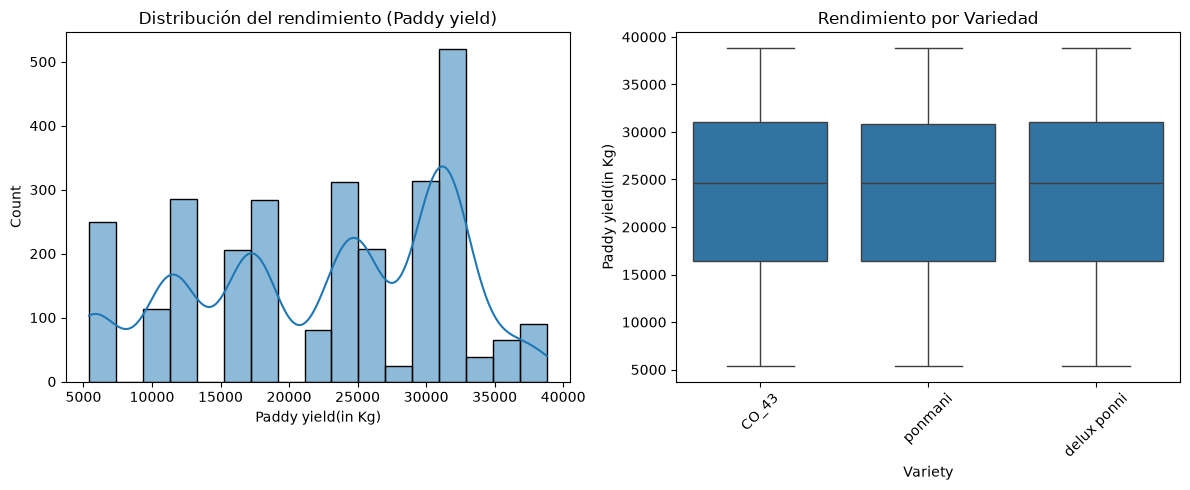

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Histograma de la variable objetivo
sns.histplot(df['Paddy yield(in Kg)'], kde=True, ax=ax[0])
ax[0].set_title('Distribución del rendimiento (Paddy yield)')

# Boxplot de Variedad vs Rendimiento
sns.boxplot(x='Variety', y='Paddy yield(in Kg)', data=df, ax=ax[1])
ax[1].set_title('Rendimiento por Variedad')
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Las visualizaciones muestran la distribución de la variable dependiente y cómo varía el rendimiento de acuerdo con el tipo de variedad sembrada, proporcionando información clave sobre posibles segmentaciones del modelo.

### 3. Limpieza de Datos

In [5]:
# Verificación de valores nulos y duplicados
nulos = df.isnull().sum()[df.isnull().sum() > 0]
duplicados = df.duplicated().sum()

print("Valores nulos:", nulos if not nulos.empty else "Ninguno")
print("Duplicados encontrados:", duplicados)

# Eliminación de registros duplicados
df = df.drop_duplicates().reset_index(drop=True)

Valores nulos: Ninguno
Duplicados encontrados: 451


Se eliminaron los registros duplicados detectados para evitar sesgos en el entrenamiento del modelo. No se detectaron valores nulos. A continuación, se tratan los valores atípicos y se codifican las variables categóricas.

In [6]:
# Tratamiento de valores atípicos mediante el método de Rango Intercuartílico (IQR)
Q1 = df['Paddy yield(in Kg)'].quantile(0.25)
Q3 = df['Paddy yield(in Kg)'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filtramos los outliers en la variable objetivo
df_clean = df[(df['Paddy yield(in Kg)'] >= lower_bound) & (df['Paddy yield(in Kg)'] <= upper_bound)]

# Codificación de variables categóricas utilizando One-Hot Encoding
categorical_cols = df_clean.select_dtypes(include=['object']).columns
df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)

df_encoded.head()

,Hectares,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,Weed28D_thiobencarb,Urea_40Days,Potassh_50Days,Micronutrients_70Days,...,Wind Direction_D31_D60_WNW,Wind Direction_D61_D90_NNE,Wind Direction_D61_D90_NNW,Wind Direction_D61_D90_SE,Wind Direction_D61_D90_SW,Wind Direction_D91_D120_NW,Wind Direction_D91_D120_S,Wind Direction_D91_D120_SSE,Wind Direction_D91_D120_W,Wind Direction_D91_D120_WSW
0,6,150,75.0,120,6,240,12,162.78,62.28,90,...,False,False,True,False,False,False,False,False,False,True
1,6,150,75.0,120,6,240,12,162.78,62.28,90,...,False,False,False,True,False,False,False,True,False,False
2,6,150,75.0,120,6,240,12,162.78,62.28,90,...,False,True,False,False,False,False,False,False,True,False
3,6,150,75.0,120,6,240,12,162.78,62.28,90,...,True,False,False,True,False,False,True,False,False,False
4,6,150,75.0,120,6,240,12,162.78,62.28,90,...,False,False,False,False,True,True,False,False,False,False
